In [1]:

# FINAL DAY 9 — Portfolio Robustness
# Alternative Allocations and Historical Subperiods

import pandas as pd
import numpy as np
from pathlib import Path

# Load master data
master = pd.read_csv(
    "../data/processed/us_macro_etf_master_2008_2025.csv",
    parse_dates=["observation_date"]
).sort_values("observation_date").reset_index(drop=True)

assets = ["SPY", "IEF", "GLD"]

# Load historical risk-free rates
rf = pd.read_csv(
    "../data/processed/us_3m_treasury_yield_2007_2025.csv",
    parse_dates=["observation_date"]
).sort_values("observation_date")

rf["month"] = rf["observation_date"].dt.to_period("M")

# GS3M: annualized yield in percentage units
# Previous-month rate as approximate monthly return
rf["rf_monthly_decimal"] = rf["GS3M"].shift(1) / 1200

study = master.copy()
study["month"] = study["observation_date"].dt.to_period("M")

study = study.merge(
    rf[["month", "rf_monthly_decimal"]],
    on="month",
    how="left",
    validate="one_to_one"
)

assert len(study) == 216
assert study[assets].notna().all().all()
assert study["rf_monthly_decimal"].notna().all()

# Keep equity exposure constant at 60%
allocations = {
    "60/40 (0% Gold)": [0.60, 0.40, 0.00],
    "60/30/10":        [0.60, 0.30, 0.10],
    "60/20/20":        [0.60, 0.20, 0.20],
    "60/10/30":        [0.60, 0.10, 0.30]
}

# Non-overlapping historical subperiods
periods = {
    "Full Sample": (2008, 2025),
    "2008–2013": (2008, 2013),
    "2014–2019": (2014, 2019),
    "2020–2025": (2020, 2025)
}

robustness_rows = []

for period_name, (start_year, end_year) in periods.items():

    subset = study.loc[
        study["observation_date"].dt.year.between(
            start_year, end_year
        )
    ].copy()

    asset_returns = subset[assets].to_numpy() / 100
    rf_returns = subset["rf_monthly_decimal"].to_numpy()

    for portfolio_name, allocation in allocations.items():

        w = np.array(allocation)

        # Monthly rebalanced portfolio returns
        returns = asset_returns @ w

        # Wealth path including initial value
        wealth = np.concatenate([
            [1.0],
            np.cumprod(1 + returns)
        ])

        n = len(returns)

        cagr = wealth[-1] ** (12 / n) - 1

        annual_vol = (
            returns.std(ddof=1) * np.sqrt(12)
        )

        excess = returns - rf_returns

        sharpe = (
            excess.mean()
            / excess.std(ddof=1)
            * np.sqrt(12)
        )

        max_drawdown = (
            wealth / np.maximum.accumulate(wealth) - 1
        ).min()

        robustness_rows.append({
            "Period": period_name,
            "Portfolio": portfolio_name,
            "Months": n,
            "CAGR (%)": cagr * 100,
            "Annual Volatility (%)": annual_vol * 100,
            "Sharpe Ratio": sharpe,
            "Max Drawdown (%)": max_drawdown * 100
        })

portfolio_robustness = pd.DataFrame(robustness_rows)

print("PORTFOLIO ROBUSTNESS BY SUBPERIOD:")
display(portfolio_robustness.round(3))

print("\nCAGR COMPARISON:")
cagr_comparison = portfolio_robustness.pivot(
    index="Period",
    columns="Portfolio",
    values="CAGR (%)"
).reindex(periods.keys())

display(cagr_comparison.round(3))

print("\nSHARPE RATIO COMPARISON:")
sharpe_comparison = portfolio_robustness.pivot(
    index="Period",
    columns="Portfolio",
    values="Sharpe Ratio"
).reindex(periods.keys())

display(sharpe_comparison.round(3))

# Validation
assert len(portfolio_robustness) == 16
assert (portfolio_robustness["Months"] > 0).all()

# Reconcile full-sample findings with Day 8
full = portfolio_robustness.set_index(
    ["Period", "Portfolio"]
)

assert np.isclose(
    full.loc[("Full Sample", "60/40 (0% Gold)"), "CAGR (%)"],
    8.114,
    atol=0.02
)

assert np.isclose(
    full.loc[("Full Sample", "60/20/20"), "CAGR (%)"],
    9.541,
    atol=0.02
)

print("\nSTEP 1 VALIDATION PASSED")


PORTFOLIO ROBUSTNESS BY SUBPERIOD:


,Period,Portfolio,Months,CAGR (%),Annual Volatility (%),Sharpe Ratio,Max Drawdown (%)
0,Full Sample,60/40 (0% Gold),216,8.114,9.626,0.720,-28.490
1,Full Sample,60/30/10,216,8.839,9.893,0.772,-28.277
2,Full Sample,60/20/20,216,9.541,10.397,0.803,-28.116
3,Full Sample,60/10/30,216,10.220,11.108,0.815,-28.178
4,2008–2013,60/40 (0% Gold),72,6.392,10.276,0.618,-28.490
5,2008–2013,60/30/10,72,6.608,10.818,0.611,-28.277
6,2008–2013,60/20/20,72,6.780,11.696,0.588,-28.116
7,2008–2013,60/10/30,72,6.907,12.840,0.556,-28.178
8,2014–2019,60/40 (0% Gold),72,8.832,6.421,1.218,-6.859
9,2014–2019,60/30/10,72,8.876,6.602,1.194,-6.455



CAGR COMPARISON:


Portfolio,60/10/30,60/20/20,60/30/10,60/40 (0% Gold)
Period,,,,
Full Sample,10.220,9.541,8.839,8.114
2008–2013,6.907,6.780,6.608,6.392
2014–2019,8.920,8.905,8.876,8.832
2020–2025,14.991,13.030,11.079,9.138



SHARPE RATIO COMPARISON:


Portfolio,60/10/30,60/20/20,60/30/10,60/40 (0% Gold)
Period,,,,
Full Sample,0.815,0.803,0.772,0.720
2008–2013,0.556,0.588,0.611,0.618
2014–2019,1.060,1.136,1.194,1.218
2020–2025,0.982,0.862,0.724,0.573



STEP 1 VALIDATION PASSED


In [2]:

# FINAL DAY 9 — Rebalancing Robustness

asset_returns = study[assets].to_numpy(dtype=float) / 100
risk_free = study["rf_monthly_decimal"].to_numpy(dtype=float)
months = study["observation_date"].dt.month.to_numpy()

test_portfolios = {
    "Traditional 60/40": np.array([0.60, 0.40, 0.00]),
    "Diversified 60/20/20": np.array([0.60, 0.20, 0.20])
}

strategies = [
    "Monthly Rebalancing",
    "Annual Rebalancing",
    "Buy & Hold"
]

def simulate_portfolio(target, strategy):

    current_weights = target.copy()
    monthly_returns = []
    turnover = []

    for t, asset_r in enumerate(asset_returns):

        rebalance = (
            (strategy == "Monthly Rebalancing" and t > 0)
            or
            (strategy == "Annual Rebalancing"
             and t > 0 and months[t] == 1)
        )

        if rebalance:
            traded = 0.5 * np.abs(
                target - current_weights
            ).sum()

            current_weights = target.copy()
        else:
            traded = 0.0

        # Portfolio return before transaction costs
        portfolio_r = float(current_weights @ asset_r)

        monthly_returns.append(portfolio_r)
        turnover.append(traded)

        # Allow weights to drift after asset returns
        current_weights = (
            current_weights * (1 + asset_r)
            / (1 + portfolio_r)
        )

    return np.array(monthly_returns), np.array(turnover)


rebalancing_rows = []

for portfolio_name, target in test_portfolios.items():

    for strategy in strategies:

        returns, turnover = simulate_portfolio(
            target, strategy
        )

        wealth = np.concatenate([
            [1.0],
            np.cumprod(1 + returns)
        ])

        excess = returns - risk_free

        rebalancing_rows.append({
            "Portfolio": portfolio_name,
            "Strategy": strategy,
            "CAGR (%)": (
                wealth[-1] ** (12 / len(returns)) - 1
            ) * 100,
            "Volatility (%)": (
                returns.std(ddof=1) * np.sqrt(12) * 100
            ),
            "Sharpe": (
                excess.mean()
                / excess.std(ddof=1)
                * np.sqrt(12)
            ),
            "Max Drawdown (%)": (
                wealth / np.maximum.accumulate(wealth)
                - 1
            ).min() * 100,
            "Annual Turnover (%)": (
                turnover.sum() / (len(returns) / 12)
                * 100
            )
        })

rebalancing_results = pd.DataFrame(rebalancing_rows)

print("REBALANCING SENSITIVITY RESULTS:")
display(rebalancing_results.round(3))

# Ensure monthly rebalancing reproduces Day 8
monthly_check = rebalancing_results.set_index(
    ["Portfolio", "Strategy"]
)

assert np.isclose(
    monthly_check.loc[
        ("Traditional 60/40", "Monthly Rebalancing"),
        "CAGR (%)"
    ],
    8.114,
    atol=0.02
)

assert np.isclose(
    monthly_check.loc[
        ("Diversified 60/20/20", "Monthly Rebalancing"),
        "CAGR (%)"
    ],
    9.541,
    atol=0.02
)

print("\nREBALANCING VALIDATION PASSED")


REBALANCING SENSITIVITY RESULTS:


,Portfolio,Strategy,CAGR (%),Volatility (%),Sharpe,Max Drawdown (%),Annual Turnover (%)
0,Traditional 60/40,Monthly Rebalancing,8.114,9.626,0.720,-28.490,10.995
1,Traditional 60/40,Annual Rebalancing,8.360,9.461,0.755,-25.701,3.882
2,Traditional 60/40,Buy & Hold,8.834,10.117,0.757,-23.931,0.000
3,Diversified 60/20/20,Monthly Rebalancing,9.541,10.397,0.803,-28.116,13.073
4,Diversified 60/20/20,Annual Rebalancing,9.697,10.252,0.827,-26.047,3.741
5,Diversified 60/20/20,Buy & Hold,9.603,10.897,0.776,-23.964,0.000



REBALANCING VALIDATION PASSED


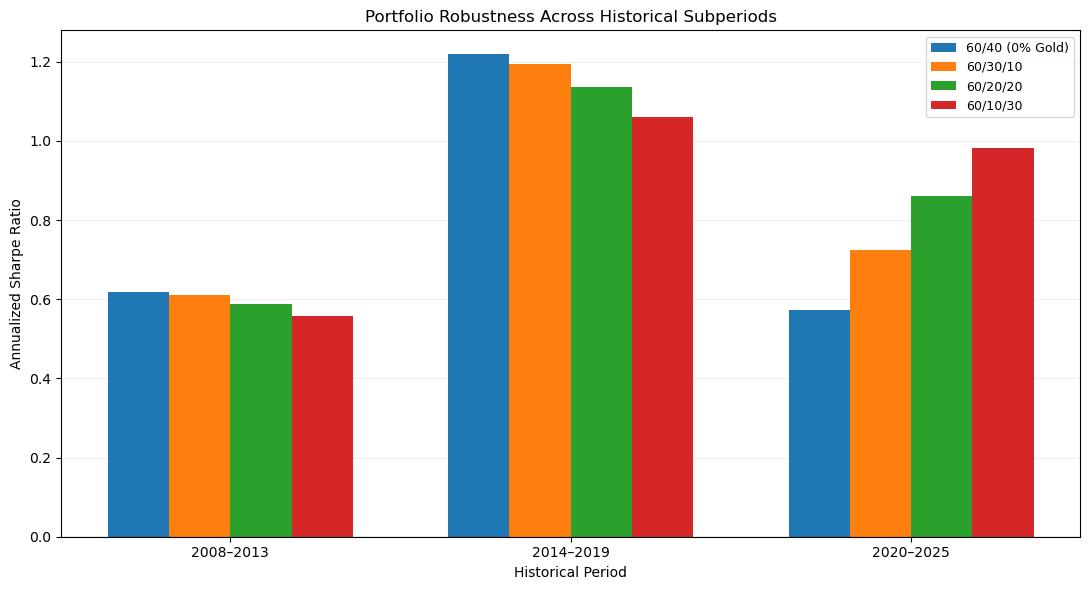

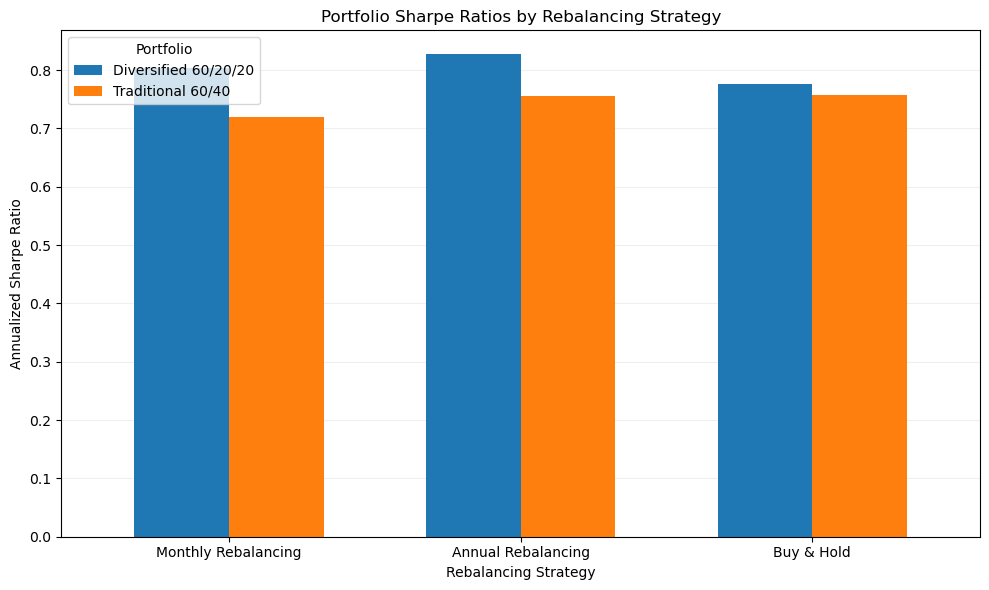

FINAL QUANTITATIVE ANALYSIS SAVED SUCCESSFULLY
Files exported: 6
Robustness observations: 16
Rebalancing comparisons: 6


In [3]:

# FINAL DAY 9 — Save Robustness Results and Figures

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

tables_dir = Path("../reports/tables")
figures_dir = Path("../reports/figures")

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Save analytical tables

portfolio_robustness.to_csv(
    tables_dir / "portfolio_subperiod_robustness.csv",
    index=False
)

cagr_comparison.to_csv(
    tables_dir / "portfolio_subperiod_cagr.csv",
    index_label="Period"
)

sharpe_comparison.to_csv(
    tables_dir / "portfolio_subperiod_sharpe.csv",
    index_label="Period"
)

rebalancing_results.to_csv(
    tables_dir / "portfolio_rebalancing_sensitivity.csv",
    index=False
)

# 2. Figure A: Subperiod Sharpe comparisons

period_order = [
    "2008–2013",
    "2014–2019",
    "2020–2025"
]

allocation_order = list(allocations.keys())

plot_data = sharpe_comparison.loc[
    period_order, allocation_order
]

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(period_order))
width = 0.18

for i, portfolio in enumerate(allocation_order):
    ax.bar(
        x + (i - 1.5) * width,
        plot_data[portfolio],
        width=width,
        label=portfolio
    )

ax.set_xticks(x)
ax.set_xticklabels(period_order)

ax.set_xlabel("Historical Period")
ax.set_ylabel("Annualized Sharpe Ratio")

ax.set_title(
    "Portfolio Robustness Across Historical Subperiods"
)

ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(fontsize=9)

fig.tight_layout()

fig.savefig(
    figures_dir / "portfolio_subperiod_robustness.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 3. Figure B: Rebalancing sensitivity

rebalancing_plot = rebalancing_results.pivot(
    index="Strategy",
    columns="Portfolio",
    values="Sharpe"
).reindex(strategies)

fig, ax = plt.subplots(figsize=(10, 6))

rebalancing_plot.plot(
    kind="bar",
    ax=ax,
    rot=0,
    width=0.65
)

ax.set_title(
    "Portfolio Sharpe Ratios by Rebalancing Strategy"
)

ax.set_xlabel("Rebalancing Strategy")
ax.set_ylabel("Annualized Sharpe Ratio")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Portfolio")

fig.tight_layout()

fig.savefig(
    figures_dir / "portfolio_rebalancing_robustness.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 4. Final validation

assert len(portfolio_robustness) == 16
assert len(rebalancing_results) == 6

expected_files = [
    tables_dir / "portfolio_subperiod_robustness.csv",
    tables_dir / "portfolio_subperiod_cagr.csv",
    tables_dir / "portfolio_subperiod_sharpe.csv",
    tables_dir / "portfolio_rebalancing_sensitivity.csv",
    figures_dir / "portfolio_subperiod_robustness.png",
    figures_dir / "portfolio_rebalancing_robustness.png"
]

assert all(path.exists() for path in expected_files)

print("FINAL QUANTITATIVE ANALYSIS SAVED SUCCESSFULLY")
print("Files exported:", len(expected_files))
print("Robustness observations:", len(portfolio_robustness))
print("Rebalancing comparisons:", len(rebalancing_results))


Final Research Findings — 2008–2025
Research question
How did inflation and monetary-policy environments coincide with changes in the relationship between US equities, intermediate-term Treasuries and gold, and what did that imply for diversified portfolios?
Central evidence
1. Regime-specific stock–bond correlations: Pearson SPY–IEF correlation was −0.262 across 96 low-CPI-inflation months, −0.135 across 86 moderate-inflation months and +0.421 across 33 high-inflation months.
2. Statistical support, conditional on sample: Fisher Z = 3.4147 (two-sided p = 0.000639); six-month circular block bootstrap 95% CI for high-minus-low correlation difference [0.102, 1.030]; 12-month blocks [0.004, 1.054]. The bootstrap does not create new independent episodes.
3. HAC regression: The SPY × High Inflation interaction for monthly IEF returns was +0.2968, HAC(12) p = 0.0044; excluding 2022 reduced this to +0.1677, p = 0.1133. OLS R² = 0.081. Regression slopes are not identical to Pearson correlations.
4. Portfolio outcomes: Monthly-rebalanced 60/40 had CAGR 8.114%, annualized volatility 9.626%, Sharpe 0.720, maximum drawdown −28.490%. The 60/20/20 portfolio had CAGR 9.541%, volatility 10.397%, Sharpe 0.803, maximum drawdown −28.116%.
5. Heterogeneous stress performance: The 60/20/20 portfolio underperformed 60/40 by 1.575 percentage points in 2008 but outperformed by 2.900 points in 2020 and 2.803 points in 2022.
6. Subperiod instability: 60/40 had higher Sharpe ratios than 60/20/20 in 2008–2013 (0.618 vs 0.588) and 2014–2019 (1.218 vs 1.136). The ordering reversed in 2020–2025 (0.573 vs 0.862).
7. Rebalancing sensitivity: 60/20/20 Sharpe exceeded 60/40 for monthly rebalance (0.803 vs 0.720), annual rebalance (0.827 vs 0.755), and buy-and-hold (0.776 vs 0.757), although the last difference was small.
Economic interpretation
The observed diversification benefit of bonds was lower in certain high-inflation months, and replacing 20 percentage points of IEF with GLD improved full-sample historical returns and Sharpe ratio. However, the portfolio's full-sample volatility increased, and gold was not the superior risk-adjusted choice in every historical subperiod. These results support regime-aware risk analysis, not a universal gold allocation or an inflation-based tactical strategy.
Most important limitations
- The inflation categories use realized contemporaneous CPI values, not information available to investors at trade time.
- High-inflation months are temporally clustered and the statistical result is sensitive to 2022.
- Observed regression relationships are associative, not causal; the models have limited explanatory power.
- Results are from one US ETF universe in one historical window, with retrospective weights and selected stress episodes.
- Rebalancing turnover has been calculated, but trading costs and taxes have not been deducted.
- Neither the correlation tests nor the portfolio comparisons demonstrate reliable out-of-sample predictive performance.
Final research conclusion
Macroeconomic environments coincided with material differences in historical cross-asset behavior, but investment implications depended on the market episode and implementation. A careful presentation should pair the full-sample result with the 2022 exclusion and subperiod robustness evidence.